# CD20 (MS4A1) in single B cells — dropout or cell state?

**Question.** CD20 is the canonical B-cell marker, but single-cell RNA-seq
captures only a fraction of each cell's RNA, so a gene can be present yet read
as zero. When **34 of 95 B cells** read zero for MS4A1, is that a *measurement
failure* or *real biology*?

This notebook is the readable, run-along version of the analysis in
`scripts/01_build_atlas.py` and `scripts/02_cd20_audit.py`. All figures and
tables below are live outputs — run the notebook top to bottom to regenerate
them.

## 0. Setup

The reusable analysis helpers live in `src/immune_atlas.py`, so the notebook
stays short and every step is inspectable.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*TBB threading layer.*")
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "src").exists():       # running from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from immune_atlas import (
    B_PANEL, PLASMA_PANEL, audit_figure, binomial_dropout,
    annotate_by_markers, cluster, dropout_audit, expression_frame, load_data,
)

sc.settings.verbosity = 0
pd.set_option("display.max_columns", 20)
print("Project root:", ROOT)

Project root: /home/tarun/Documents/RnD/tharun_internship/sc_immune_atlas


## 1. Load the public dataset

We use the 700-cell reduced PBMC dataset distributed with Scanpy. It comes with
coarse labels (`bulk_labels`) — we will **hide** those while clustering and only
use them afterwards to check our work.

In [2]:
adata = load_data()
print(f"Cells: {adata.n_obs}   Genes: {adata.n_vars}")
print("Metadata columns:", list(adata.obs.columns))
adata.obs["bulk_labels"].value_counts().to_frame("cells")

Cells: 700   Genes: 765
Metadata columns: ['bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain']


,cells
bulk_labels,
Dendritic,240
CD14+ Monocyte,129
CD19+ B,95
CD4+/CD25 T Reg,68
CD8+ Cytotoxic T,54
CD8+/CD45RA+ Naive Cytotoxic,43
CD56+ NK,31
CD4+/CD45RO+ Memory,19
CD34+,13


## 2. Build an unsupervised atlas (labels withheld)

PCA → nearest neighbours → Leiden clustering → UMAP. No cell-type label is used
here; clusters are named afterwards from marker panels. This gives us an
independent way to decide which cells are B cells.

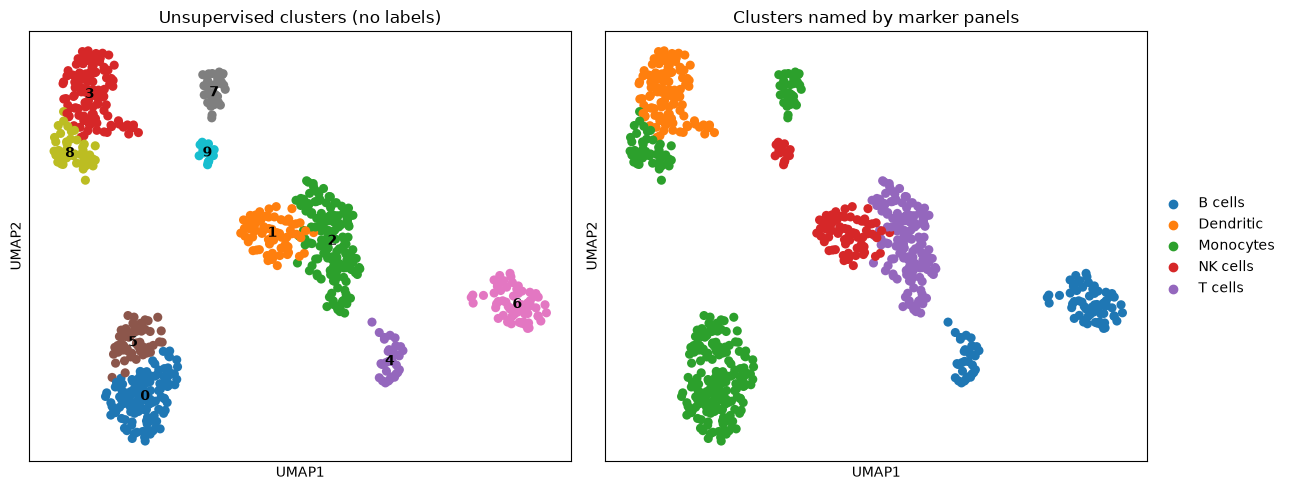

In [3]:
atlas = cluster(adata, resolution=1.0, seed=0)
expr = expression_frame(atlas)
names = annotate_by_markers(expr, atlas.obs["leiden"])
atlas.obs["cell_type"] = atlas.obs["leiden"].map(names).astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, colour, title in zip(
    axes, ["leiden", "cell_type"],
    ["Unsupervised clusters (no labels)", "Clusters named by marker panels"],
):
    sc.pl.umap(atlas, color=colour, ax=ax, show=False, title=title,
               legend_loc="on data" if colour == "leiden" else "right margin")
fig.tight_layout()
plt.show()

### Validation only — compare with the withheld labels

This check happens *after* annotation. Of the 95 `CD19+ B` cells, 92 fall in
marker-defined B clusters.

In [4]:
pd.crosstab(atlas.obs["cell_type"], atlas.obs["bulk_labels"].astype(str))

bulk_labels,CD14+ Monocyte,CD19+ B,CD34+,CD4+/CD25 T Reg,CD4+/CD45RA+/CD25- Naive T,CD4+/CD45RO+ Memory,CD56+ NK,CD8+ Cytotoxic T,CD8+/CD45RA+ Naive Cytotoxic,Dendritic
cell_type,,,,,,,,,,
B cells,1,92,0,0,3,0,0,3,0,0
Dendritic,0,0,0,0,0,0,0,0,0,114
Monocytes,128,0,0,0,0,1,0,3,0,125
NK cells,0,0,13,2,0,0,30,32,7,0
T cells,0,3,0,66,5,18,1,16,36,1


## 3. The audit: 34 of 95 B cells read zero for MS4A1

`dropout_audit` restricts to the 95 coarse-labelled B cells, then compares
MS4A1-zero cells with MS4A1-positive cells across several independent signals.

In [5]:
audit = dropout_audit(adata)
print(f"B cells: {audit['n_b']}")
print(f"MS4A1-zero: {audit['n_ms4a1_zero']} ({audit['zero_fraction']:.1%})")

audit["detection"]

B cells: 95
MS4A1-zero: 34 (35.8%)


,gene,detected,fraction
0,CD79A,94,0.989474
1,CD79B,83,0.873684
2,MS4A1,61,0.642105
3,CD74,95,1.000000
4,HLA-DRA,86,0.905263
5,MZB1,51,0.536842


## 4. Hypothesis: this is technical dropout

A simple binomial thought experiment: if a B cell holds ~10 MS4A1 molecules and
the assay captures ~10% of them, the chance of seeing zero is

$$(1 - 0.10)^{10} \approx 0.35$$

That is almost exactly the observed 35.8%. Tempting — but a matching number is
not proof. We need to test what dropout *predicts* about the zero cells.

In [6]:
p_zero = binomial_dropout(mean_molecules=10, capture=0.10)
print(f"(1 - 0.10)^10 = {p_zero:.3f}  ->  {p_zero:.1%} expected zeros")
print(f"Observed        = {audit['n_ms4a1_zero']}/{audit['n_b']}"
      f" = {audit['zero_fraction']:.1%}")

(1 - 0.10)^10 = 0.349  ->  34.9% expected zeros
Observed        = 34/95 = 35.8%


## 5. Testing the hypothesis

If zeros were caused by failed capture, the zero cells should look **worse**:
less RNA overall and loss of other B markers. We check three things:

| Signal | What dropout predicts |
|---|---|
| **CD79A** (another B-lineage gene) | also often missing |
| **MZB1** (plasma-cell marker) | no reason to be enriched |
| **UMI counts** (captured RNA) | lower in zero cells |

In [7]:
zero, pos = audit["zero_cells"], audit["pos_cells"]
b = audit["b_expr"]

def n_detected(gene, cells):
    return int((b.loc[cells, gene] > 0).sum())

evidence = pd.DataFrame({
    "Check": [
        "CD79A detected (B lineage)",
        "MZB1 detected (plasma)",
        "MZB1-high",
        "Mean UMI counts",
    ],
    f"MS4A1 = 0 (n={len(zero)})": [
        f"{n_detected('CD79A', zero)}/{len(zero)}",
        f"{n_detected('MZB1', zero)}/{len(zero)}",
        f"{int((audit['plasma_score'].loc[zero] > 0.5).sum())}/{len(zero)}",
        f"{audit['depth'].loc[zero].mean():,.0f}",
    ],
    f"MS4A1 > 0 (n={len(pos)})": [
        f"{n_detected('CD79A', pos)}/{len(pos)}",
        f"{n_detected('MZB1', pos)}/{len(pos)}",
        f"{int((audit['plasma_score'].loc[pos] > 0.5).sum())}/{len(pos)}",
        f"{audit['depth'].loc[pos].mean():,.0f}",
    ],
})
evidence

,Check,MS4A1 = 0 (n=34),MS4A1 > 0 (n=61)
0,CD79A detected (B lineage),33/34,61/61
1,MZB1 detected (plasma),30/34,21/61
2,MZB1-high,28/34,4/61
3,Mean UMI counts,"4,210","3,482"


### The four-panel audit

**A** — many genes mark B cells; MS4A1 is only one. **B** — sampling predicts
the zero, but does not explain *why* it happens. **C** — CD79A stays on while
MZB1 is enriched. **D** — the zero cells contain **more** RNA, not less.

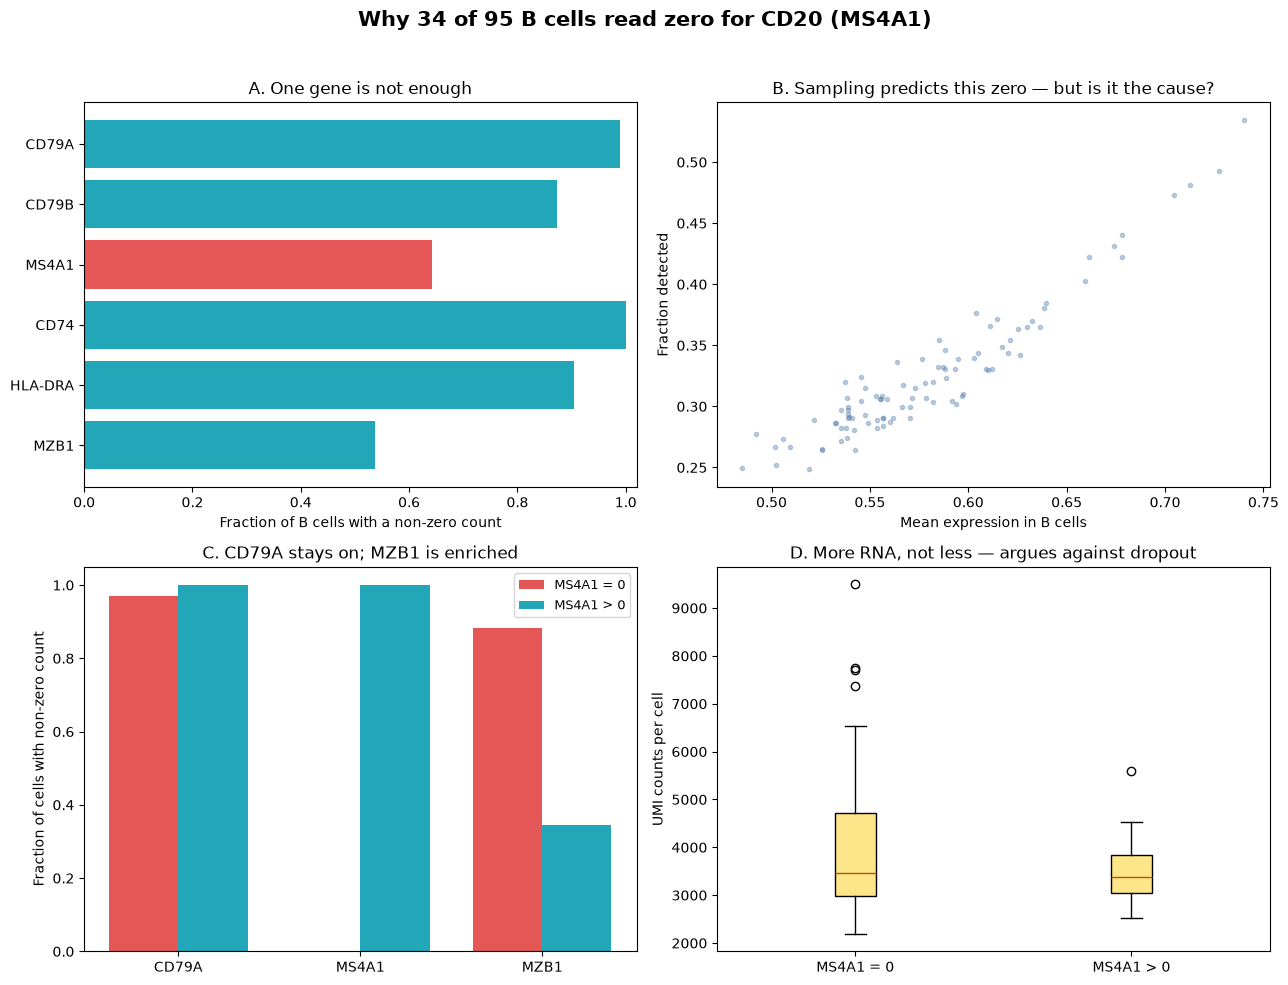

In [8]:
fig = audit_figure(audit)
plt.show()

## 6. Conclusion

The dropout hypothesis is **not supported**. The MS4A1-zero cells keep CD79A,
have higher UMI counts and are enriched for the plasma marker MZB1. CD20 is lost
when B cells differentiate into plasmablasts, so most of these zeros are best
explained as **genuine CD20-low plasmablasts**, not failed measurement.

The lesson: **CD20 marks a B-cell *state*, not B-cell identity.** A single gene
gives the same zero for two different reasons; a small marker panel plus basic
QC separates them.

### Limitations

- The reduced matrix has only 765 genes; **MZB1 is the only plasma marker
  present** (PRDM1, XBP1, JCHAIN and immunoglobulins are absent).
- `CD19+ B` is a coarse sort label that already includes plasma cells.
- One donor, one dataset, no protein-level (CITE-seq) confirmation.

### Next steps

1. Repeat on the full PBMC dataset with the complete plasma gene panel.
2. Confirm the plasma transcriptional program in the MS4A1-zero subset.
3. Validate CD20 surface protein with CITE-seq or flow cytometry.

## References

1. Pavlasova G, Mráz M. The regulation and function of CD20: an "enigma" of
   B-cell biology and targeted therapy. *Haematologica*. 2020;105(6):1494–1506.
   doi:10.3324/haematol.2019.243543
2. Kharchenko PV, Silberstein L, Scadden DT. Bayesian approach to single-cell
   differential expression analysis. *Nature Methods*. 2014;11:740–742.
   doi:10.1038/nmeth.2967
3. Wolf FA, Angerer P, Theis FJ. SCANPY: large-scale single-cell gene expression
   data analysis. *Genome Biology*. 2018;19(1):15.
   doi:10.1186/s13059-017-1382-0
4. Zheng GXY et al. Massively parallel digital transcriptional profiling of
   single cells. *Nature Communications*. 2017;8:14049.
   doi:10.1038/ncomms14049
5. Janeway CA Jr et al. *Janeway's Immunobiology*. 9th ed. Garland Science; 2017.

> The 34/95 observation and its interpretation are the result of this analysis;
> the references support the background and biological interpretation.